# Marvel CPG Data V3 — Module 2 Segmented OOS Model Development

**Data version:** V3  
**Objective:** predict whether a store × SKU will experience at least one observed OOS day during the next seven days.

**Targets:** Precision ≥ 0.75, Recall ≥ 0.70, ROC-AUC ≥ 0.80.

March and April are development folds. May is the iterative validation checkpoint required by the project workflow. June remains the untouched out-of-time test and is not loaded.

## Modeling and leakage rules

- Labels require all seven future Sell-out rows to be observed; imputed states never become target labels.
- Current missing-day inventory is reconstructed from last observed inventory, estimated demand, and actual deliveries known by prediction time.
- Future `actual_delivery` and future `restock_units` are forbidden features.
- Future inbound features use only orders already placed by date `t`, their scheduled delivery dates, and their still-pending status at `t`.
- Segment-specific thresholds and standalone segment models are tuned only on March/April.
- May is the validation checkpoint; June is untouched and is not used for tuning.

In [1]:
from __future__ import annotations

import gc
import json
import os
import warnings
from dataclasses import dataclass
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/marvel-v3-mpl")
warnings.filterwarnings("ignore")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

SEED = 650
TEST_START = pd.Timestamp("2026-06-01")
MIN_PRECISION, MIN_RECALL, MIN_AUC = 0.75, 0.70, 0.80
# Development threshold uses a recall buffer for temporal robustness; the formal target remains 0.70.
DEV_RECALL_FLOOR = 0.75
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "data/raw/fact_sell_out.csv").exists())
DATA = ROOT / "data/raw"
OUTPUT = ROOT / "outputs/v3/module2"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Repository:", ROOT)
print("Locked test begins:", TEST_START.date())

Repository: /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote
Locked test begins: 2026-06-01


## 1. Load only pre-June data and build the canonical panel

In [2]:
def read_before_test(path, date_col, chunksize=250_000):
    parts = []
    for chunk in pd.read_csv(path, parse_dates=[date_col], chunksize=chunksize):
        parts.append(chunk.loc[chunk[date_col] < TEST_START])
    return pd.concat(parts, ignore_index=True)

stores = pd.read_csv(DATA / "dim_stores.csv")
products = pd.read_csv(DATA / "dim_products.csv")
promotions = pd.read_csv(DATA / "dim_promotions.csv", parse_dates=["start_date", "end_date"])
sell_out = read_before_test(DATA / "fact_sell_out.csv", "date")
deliveries = pd.read_csv(DATA / "fact_deliveries.csv", parse_dates=["order_date", "scheduled_delivery", "actual_delivery"])
deliveries = deliveries.loc[(deliveries.order_date < TEST_START) & (deliveries.actual_delivery < TEST_START)].copy()

pairs = (
    sell_out[["store_id", "sku_id"]].drop_duplicates()
    .merge(stores[["store_id", "channel", "region", "segment_tier"]], on="store_id", validate="many_to_one")
    .merge(products[["sku_id", "category", "is_msl"]], on="sku_id", validate="many_to_one")
)
dates = pd.DataFrame({"date": pd.date_range(sell_out.date.min(), pd.Timestamp("2026-05-31"))})
pairs["_k"] = dates["_k"] = 1
panel = pairs.merge(dates, on="_k").drop(columns="_k")
panel = panel.merge(sell_out, on=["date", "store_id", "sku_id"], how="left", validate="one_to_one")
panel = panel.sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True)
panel["is_reported"] = panel.inventory_level.notna()
panel["weekday"] = panel.date.dt.dayofweek
print(f"Panel rows: {len(panel):,} | pairs: {len(pairs):,} | coverage: {panel.is_reported.mean():.2%}")

Panel rows: 2,257,500 | pairs: 4,375 | coverage: 91.84%


## 2. Reconstruct current state and create leakage-safe replenishment features

In [3]:
# Actual receipts are usable only on/after their event date. They repair missing-day state but are not future features.
receipts = deliveries.groupby(["actual_delivery", "store_id", "sku_id"], as_index=False).agg(
    actual_receipt_units=("units_delivered", "sum"), actual_receipts=("delivery_id", "size")
).rename(columns={"actual_delivery": "date"})
panel = panel.merge(receipts, on=["date", "store_id", "sku_id"], how="left")
panel[["actual_receipt_units", "actual_receipts"]] = panel[["actual_receipt_units", "actual_receipts"]].fillna(0)

# Planned promotion calendar is known in advance.
promo_parts = []
for r in promotions.itertuples(index=False):
    promo_parts.append(pd.DataFrame({
        "date": pd.date_range(r.start_date, min(r.end_date, pd.Timestamp("2026-05-31"))),
        "channel": r.channel, "category": r.category,
        "promo_planned": 1, "promo_discount_planned": r.discount_pct,
    }))
promo_calendar = pd.concat(promo_parts, ignore_index=True).drop_duplicates(["date", "channel", "category"])
panel = panel.merge(promo_calendar, on=["date", "channel", "category"], how="left")
panel["promo_planned"] = panel.promo_planned.fillna(0).astype("int8")
panel["promo_discount_planned"] = panel.promo_discount_planned.fillna(0)

pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
panel["sales_median_28"] = pair.units_sold_daily.transform(lambda s: s.shift(1).rolling(28, min_periods=5).median())
panel["sales_weekday_8"] = panel.groupby(["store_id", "sku_id", "weekday"], observed=True).units_sold_daily.transform(
    lambda s: s.shift(1).rolling(8, min_periods=2).median()
)
fallback = panel.groupby(["channel", "category"], observed=True).units_sold_daily.transform("median")
panel["sales_estimate"] = panel.sales_weekday_8.fillna(panel.sales_median_28).fillna(fallback).clip(lower=0)

# Conservative promotion factor learned from the historical period before all validation folds.
factor_source = panel.loc[(panel.date <= pd.Timestamp("2026-02-21")) & panel.is_reported & ~panel.is_out_of_stock.fillna(False)].copy()
normal = factor_source.loc[panel.loc[factor_source.index, "promo_planned"].eq(0)].groupby(["channel", "category"]).units_sold_daily.mean()
promoted = factor_source.loc[panel.loc[factor_source.index, "promo_planned"].eq(1)].groupby(["channel", "category"]).units_sold_daily.mean()
promo_factor = (promoted / normal).clip(.8, 1.8).replace([np.inf, -np.inf], np.nan).fillna(1).to_dict()
panel["promo_factor"] = [promo_factor.get((c, k), 1.0) if p else 1.0 for c, k, p in zip(panel.channel, panel.category, panel.promo_planned)]
panel["sales_estimate"] *= panel.promo_factor
panel["sales_state"] = panel.units_sold_daily.fillna(panel.sales_estimate)

# Each observed row starts a new reconciliation segment. Missing rows consume estimated sales and add known receipts.
pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
panel["inventory_locf"] = pair.inventory_level.ffill()
panel["observation_segment"] = pair.is_reported.cumsum()
keys = [panel.store_id, panel.sku_id, panel.observation_segment]
panel["missing_sales"] = np.where(panel.is_reported, 0, panel.sales_estimate)
panel["missing_receipts"] = np.where(panel.is_reported, 0, panel.actual_receipt_units)
panel["gap_sales_cumulative"] = panel.groupby(keys, observed=True).missing_sales.cumsum()
panel["gap_receipts_cumulative"] = panel.groupby(keys, observed=True).missing_receipts.cumsum()
panel["inventory_reconciled"] = np.where(
    panel.is_reported,
    panel.inventory_level,
    (panel.inventory_locf + panel.gap_receipts_cumulative - panel.gap_sales_cumulative).clip(lower=0),
)
last_report = panel.date.where(panel.is_reported)
panel["days_since_report"] = (panel.date - last_report.groupby([panel.store_id, panel.sku_id]).ffill()).dt.days.fillna(999)

In [4]:
# Expand each already-placed, still-pending order to prediction dates where its scheduled arrival is 1-7 days away.
pending_rows = []
for r in deliveries.itertuples(index=False):
    first_t = max(r.order_date, r.scheduled_delivery - pd.Timedelta(days=7), pd.Timestamp("2025-01-01"))
    last_t = min(r.scheduled_delivery - pd.Timedelta(days=1), r.actual_delivery - pd.Timedelta(days=1), pd.Timestamp("2026-05-31"))
    if first_t <= last_t:
        d = pd.date_range(first_t, last_t)
        pending_rows.append(pd.DataFrame({
            "date": d, "store_id": r.store_id, "sku_id": r.sku_id,
            "pending_units": r.units_ordered,
            "days_to_scheduled": (r.scheduled_delivery - d).days,
        }))
pending = pd.concat(pending_rows, ignore_index=True)
pending["pending_units_3d_component"] = np.where(pending.days_to_scheduled <= 3, pending.pending_units, 0)
pending_daily = pending.groupby(["date", "store_id", "sku_id"], as_index=False).agg(
    pending_units_7d=("pending_units", "sum"),
    pending_units_3d=("pending_units_3d_component", "sum"),
    pending_orders_7d=("pending_units", "size"),
    days_to_next_scheduled=("days_to_scheduled", "min"),
)
panel = panel.merge(pending_daily, on=["date", "store_id", "sku_id"], how="left")
for c in ["pending_units_7d", "pending_units_3d", "pending_orders_7d"]:
    panel[c] = panel[c].fillna(0)
panel["days_to_next_scheduled"] = panel.days_to_next_scheduled.fillna(99)

# Historical receipt reliability: only completed receipts on/before t contribute.
pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
panel["receipt_event"] = panel.actual_receipts.gt(0).astype("int8")
panel["receipt_units_28d"] = pair.actual_receipt_units.transform(lambda s: s.rolling(28, min_periods=1).sum())
panel["receipt_events_28d"] = pair.receipt_event.transform(lambda s: s.rolling(28, min_periods=1).sum())
last_receipt = panel.date.where(panel.receipt_event.eq(1))
panel["days_since_receipt"] = (panel.date - last_receipt.groupby([panel.store_id, panel.sku_id]).ffill()).dt.days.fillna(999)
print(f"Pending-order feature rows: {len(pending_daily):,}")

Pending-order feature rows: 426,855


## 3. Demand, inventory trajectory, and strict labels

In [5]:
pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
for days in [3, 7, 14, 28]:
    panel[f"sales_velocity_{days}d"] = pair.sales_state.transform(lambda s: s.rolling(days, min_periods=1).mean())
panel["sales_acceleration"] = panel.sales_velocity_7d - panel.sales_velocity_28d
panel["inventory_change_3d"] = panel.inventory_reconciled - pair.inventory_reconciled.shift(3)
panel["inventory_change_7d"] = panel.inventory_reconciled - pair.inventory_reconciled.shift(7)
panel["days_of_cover"] = panel.inventory_reconciled / (panel.sales_velocity_14d + .25)
panel["pending_cover_7d"] = panel.pending_units_7d / (panel.sales_velocity_14d * 7 + 1)
panel["report_coverage_7d"] = pair.is_reported.transform(lambda s: s.rolling(7, min_periods=1).mean())
panel["oos_numeric"] = panel.is_out_of_stock.astype("float")
panel["oos_rate_28d"] = pair.oos_numeric.transform(lambda s: s.shift(1).rolling(28, min_periods=1).mean())
panel["month"] = panel.date.dt.month.astype("int8")
panel["dow"] = panel.date.dt.dayofweek.astype("int8")

# Known planned promotions in the next seven days.
panel["promo_days_next_7d"] = 0
for h in range(1, 8):
    panel["promo_days_next_7d"] += pair.promo_planned.shift(-h).fillna(0).astype("int8")

# Ground truth is allowed only when all seven future rows are observed.
future_complete = np.ones(len(panel), dtype=bool)
future_oos = np.zeros(len(panel), dtype=bool)
first_oos_day = np.full(len(panel), np.nan)
future_restock = np.zeros(len(panel), dtype=bool)
for h in range(1, 8):
    complete_h = pair.is_reported.shift(-h).fillna(False).to_numpy(bool)
    oos_h = pair.is_out_of_stock.shift(-h).fillna(False).to_numpy(bool)
    restock_h = pair.restock_units.shift(-h).fillna(0).gt(0).to_numpy(bool)
    future_complete &= complete_h
    future_oos |= oos_h
    future_restock |= restock_h
    first_oos_day[np.isnan(first_oos_day) & oos_h] = h
panel["future_7d_complete"] = future_complete
panel["target"] = np.where(future_complete, future_oos.astype("int8"), np.nan)
panel["future_restock_7d"] = future_restock
panel["first_oos_day"] = first_oos_day

label_summary = panel.loc[panel.date.between("2026-03-01", "2026-05-24")].groupby(panel.date.dt.month).agg(
    candidates=("date", "size"), complete_labels=("future_7d_complete", "sum"), positives=("target", lambda s: s.eq(1).sum())
)
label_summary["coverage"] = label_summary.complete_labels / label_summary.candidates
label_summary["base_rate"] = label_summary.positives / label_summary.complete_labels
display(label_summary)

,candidates,complete_labels,positives,coverage,base_rate
date,,,,,
3,135625,74587,12062,0.549950,0.161717
4,131250,72212,9709,0.550187,0.134451
5,105000,56598,5934,0.539029,0.104845


## 4. Feature families, temporal folds, and model utilities

In [6]:
BASELINE_NUMERIC = [
    "inventory_reconciled", "sales_velocity_3d", "sales_velocity_7d", "sales_velocity_14d", "sales_velocity_28d",
    "sales_acceleration", "inventory_change_3d", "inventory_change_7d", "days_of_cover",
    "days_since_report", "report_coverage_7d", "oos_rate_28d",
    "promo_planned", "promo_discount_planned", "promo_days_next_7d", "month", "dow", "is_msl",
]
DELIVERY_NUMERIC = [
    "pending_units_3d", "pending_units_7d", "pending_orders_7d", "days_to_next_scheduled", "pending_cover_7d",
    "receipt_units_28d", "receipt_events_28d", "days_since_receipt",
]
CATEGORICAL = ["channel", "segment_tier", "region", "category"]
FEATURE_SETS = {
    "baseline_no_pending_delivery": BASELINE_NUMERIC,
    "v3_replenishment_enriched": BASELINE_NUMERIC + DELIVERY_NUMERIC,
}

@dataclass
class Fold:
    name: str
    train_end: pd.Timestamp
    valid_start: pd.Timestamp
    valid_end: pd.Timestamp

DEV_FOLDS = [
    Fold("2026-03", pd.Timestamp("2026-02-21"), pd.Timestamp("2026-03-01"), pd.Timestamp("2026-03-24")),
    Fold("2026-04", pd.Timestamp("2026-03-23"), pd.Timestamp("2026-04-01"), pd.Timestamp("2026-04-23")),
]
MAY_FOLD = Fold("2026-05", pd.Timestamp("2026-04-23"), pd.Timestamp("2026-05-01"), pd.Timestamp("2026-05-24"))

def make_model(seed=SEED):
    return lgb.LGBMClassifier(
        n_estimators=260, learning_rate=.05, num_leaves=48, min_child_samples=45,
        subsample=.85, colsample_bytree=.85, reg_lambda=.7,
        class_weight="balanced", random_state=seed, verbosity=-1, n_jobs=4,
    )

def prepare_categories(train, valid, categorical):
    train, valid = train.copy(), valid.copy()
    for c in categorical:
        levels = pd.Index(pd.concat([train[c], valid[c]]).dropna().unique())
        train[c] = pd.Categorical(train[c], categories=levels)
        valid[c] = pd.Categorical(valid[c], categories=levels)
    return train, valid

def split_fold(frame, fold):
    eligible = frame.future_7d_complete & frame.inventory_reconciled.notna()
    train = frame.loc[eligible & frame.date.le(fold.train_end)].copy()
    valid = frame.loc[eligible & frame.date.between(fold.valid_start, fold.valid_end)].copy()
    if len(train) > 450_000:
        train = train.sample(450_000, random_state=SEED)
    return train, valid

def fit_predict(train, valid, numeric, categorical=CATEGORICAL):
    train, valid = prepare_categories(train, valid, categorical)
    features = numeric + categorical
    model = make_model()
    model.fit(train[features], train.target.astype(int), categorical_feature=categorical)
    return model, model.predict_proba(valid[features])[:, 1]

def choose_threshold(y, score, min_recall=DEV_RECALL_FLOOR):
    precision, recall, thresholds = precision_recall_curve(y, score)
    table = pd.DataFrame({"threshold": thresholds, "precision": precision[:-1], "recall": recall[:-1]})
    eligible = table.loc[table.recall >= min_recall]
    return float(eligible.sort_values(["precision", "threshold"], ascending=False).iloc[0].threshold)

def metric_row(y, score, threshold):
    pred = score >= threshold
    tp = int(((y == 1) & pred).sum()); fp = int(((y == 0) & pred).sum()); fn = int(((y == 1) & ~pred).sum())
    auc = roc_auc_score(y, score)
    precision = tp / max(tp + fp, 1); recall = tp / max(tp + fn, 1)
    return {
        "ROC_AUC": auc, "PR_AUC": average_precision_score(y, score),
        "precision": precision, "recall": recall, "TP": tp, "FP": fp, "FN": fn,
        "alerts": int(pred.sum()), "threshold": threshold,
        "meets_target": bool(precision >= MIN_PRECISION and recall >= MIN_RECALL and auc >= MIN_AUC),
    }

## 5. March/April feature-family experiment

Training baseline_no_pending_delivery 2026-03


Training baseline_no_pending_delivery 2026-04


Training v3_replenishment_enriched 2026-03


Training v3_replenishment_enriched 2026-04


,feature_set,evaluation,ROC_AUC,PR_AUC,precision,recall,TP,FP,FN,alerts,threshold,meets_target
0,baseline_no_pending_delivery,March-April pooled,0.9751,0.8517,0.8091,0.7500,13050,3080,4349,16130,0.8717,True
1,baseline_no_pending_delivery,2026-03,0.9736,0.8529,0.8135,0.7535,7230,1658,2365,8888,0.8717,True
2,baseline_no_pending_delivery,2026-04,0.9766,0.8509,0.8036,0.7458,5820,1422,1984,7242,0.8717,True
3,v3_replenishment_enriched,March-April pooled,0.9879,0.9417,0.9184,0.7501,13051,1160,4348,14211,0.9118,True
4,v3_replenishment_enriched,2026-03,0.9875,0.9440,0.9200,0.7549,7243,630,2352,7873,0.9118,True
5,v3_replenishment_enriched,2026-04,0.9883,0.9388,0.9164,0.7442,5808,530,1996,6338,0.9118,True


### Frozen feature family: **v3_replenishment_enriched**

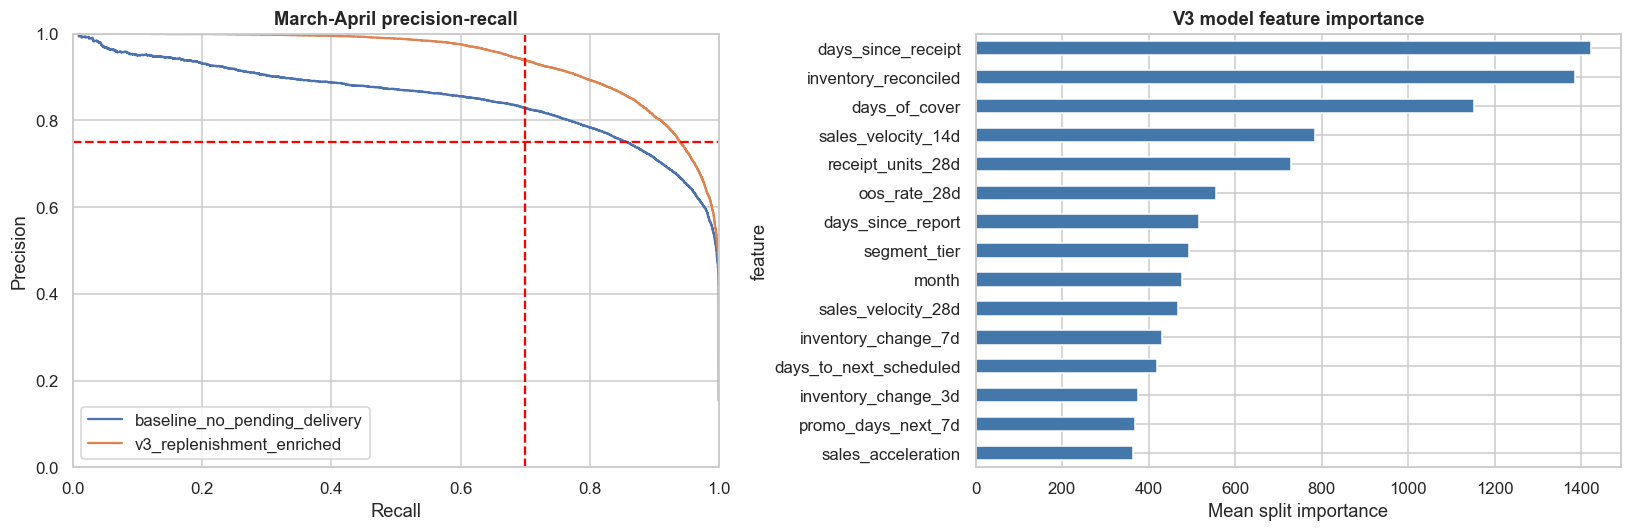

In [7]:
feature_predictions = []
feature_importance = []
for feature_name, numeric in FEATURE_SETS.items():
    for fold in DEV_FOLDS:
        print("Training", feature_name, fold.name, flush=True)
        train, valid = split_fold(panel, fold)
        model, score = fit_predict(train, valid, numeric)
        keep = valid[["date", "store_id", "sku_id", "channel", "segment_tier", "category", "target", "future_restock_7d"]].copy()
        keep["score"] = score; keep["fold"] = fold.name; keep["feature_set"] = feature_name
        feature_predictions.append(keep)
        feature_importance.append(pd.DataFrame({
            "feature_set": feature_name, "fold": fold.name,
            "feature": numeric + CATEGORICAL, "importance": model.feature_importances_,
        }))
        del train, valid, model
        gc.collect()
feature_predictions = pd.concat(feature_predictions, ignore_index=True)
feature_importance = pd.concat(feature_importance, ignore_index=True)

feature_metrics = []
feature_thresholds = {}
for name, d in feature_predictions.groupby("feature_set", observed=True):
    threshold = choose_threshold(d.target.to_numpy(int), d.score.to_numpy())
    feature_thresholds[name] = threshold
    feature_metrics.append({"feature_set": name, "evaluation": "March-April pooled", **metric_row(d.target.to_numpy(int), d.score.to_numpy(), threshold)})
    for fold, f in d.groupby("fold", observed=True):
        feature_metrics.append({"feature_set": name, "evaluation": fold, **metric_row(f.target.to_numpy(int), f.score.to_numpy(), threshold)})
feature_metrics = pd.DataFrame(feature_metrics)
display(feature_metrics.round(4))

pooled_features = feature_metrics.loc[feature_metrics.evaluation.eq("March-April pooled")].sort_values(["meets_target", "precision", "PR_AUC"], ascending=False)
selected_feature_set = pooled_features.iloc[0].feature_set
selected_numeric = FEATURE_SETS[selected_feature_set]
display(Markdown(f"### Frozen feature family: **{selected_feature_set}**"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, d in feature_predictions.groupby("feature_set", observed=True):
    p, r, _ = precision_recall_curve(d.target, d.score)
    axes[0].plot(r, p, label=name)
axes[0].axvline(.70, color="red", ls="--"); axes[0].axhline(.75, color="red", ls="--")
axes[0].set(title="March-April precision-recall", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1)); axes[0].legend()
top_imp = feature_importance.loc[feature_importance.feature_set.eq("v3_replenishment_enriched")].groupby("feature").importance.mean().nlargest(15).sort_values()
top_imp.plot.barh(ax=axes[1], color="#4477AA"); axes[1].set(title="V3 model feature importance", xlabel="Mean split importance")
plt.tight_layout(); plt.show()

## 6. Segment architecture and threshold-policy experiment

In [8]:
# Reuse shared enriched development predictions, then train standalone channel × tier models.
shared_dev = feature_predictions.loc[feature_predictions.feature_set.eq(selected_feature_set)].copy()
standalone_parts = []
for fold in DEV_FOLDS:
    train, valid = split_fold(panel, fold)
    for (channel, tier), vseg in valid.groupby(["channel", "segment_tier"], observed=True):
        tseg = train.loc[train.channel.eq(channel) & train.segment_tier.eq(tier)].copy()
        print("Standalone", fold.name, channel, tier, len(tseg), len(vseg), flush=True)
        _, score = fit_predict(tseg, vseg, selected_numeric, categorical=["region", "category"])
        keep = vseg[["date", "store_id", "sku_id", "channel", "segment_tier", "category", "target", "future_restock_7d"]].copy()
        keep["score"] = score; keep["fold"] = fold.name
        standalone_parts.append(keep)
    del train, valid
    gc.collect()
standalone_dev = pd.concat(standalone_parts, ignore_index=True)

def apply_global_threshold(predictions):
    threshold = choose_threshold(predictions.target.to_numpy(int), predictions.score.to_numpy())
    out = predictions.copy(); out["threshold"] = threshold; out["predicted"] = out.score.ge(threshold)
    return out, {"global": threshold}

def apply_segment_thresholds(predictions):
    parts, thresholds = [], {}
    for (channel, tier), d in predictions.groupby(["channel", "segment_tier"], observed=True):
        threshold = choose_threshold(d.target.to_numpy(int), d.score.to_numpy())
        thresholds[f"{channel} | {tier}"] = threshold
        x = d.copy(); x["threshold"] = threshold; x["predicted"] = x.score.ge(threshold); parts.append(x)
    return pd.concat(parts, ignore_index=True), thresholds

policy_dev = {}
policy_thresholds = {}
for architecture, predictions in {"shared_model": shared_dev, "standalone_segment_models": standalone_dev}.items():
    for policy, fn in {"global_threshold": apply_global_threshold, "segment_thresholds": apply_segment_thresholds}.items():
        governed, thresholds = fn(predictions)
        policy_dev[(architecture, policy)] = governed
        policy_thresholds[(architecture, policy)] = thresholds

policy_rows = []
for (architecture, policy), d in policy_dev.items():
    y = d.target.to_numpy(int); score = d.score.to_numpy(); pred = d.predicted.to_numpy(bool)
    tp = ((y == 1) & pred).sum(); fp = ((y == 0) & pred).sum(); fn = ((y == 1) & ~pred).sum()
    policy_rows.append({
        "architecture": architecture, "policy": policy, "evaluation": "March-April development",
        "ROC_AUC": roc_auc_score(y, score), "PR_AUC": average_precision_score(y, score),
        "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
        "TP": tp, "FP": fp, "FN": fn, "alerts": pred.sum(),
    })
policy_metrics_dev = pd.DataFrame(policy_rows)
policy_metrics_dev["meets_target"] = (
    policy_metrics_dev.precision.ge(MIN_PRECISION) & policy_metrics_dev.recall.ge(MIN_RECALL) & policy_metrics_dev.ROC_AUC.ge(MIN_AUC)
)
display(policy_metrics_dev.round(4))
selected = policy_metrics_dev.sort_values(["meets_target", "precision", "PR_AUC"], ascending=False).iloc[0]
selected_architecture, selected_policy = selected.architecture, selected.policy
display(Markdown(f"### Frozen policy: **{selected_architecture} + {selected_policy}**"))

Standalone 2026-03 Distributor Tier 1 32676 4919


Standalone 2026-03 Distributor Tier 2 19245 2651


Standalone 2026-03 Distributor Tier 3 20995 2703


Standalone 2026-03 Modern Trade Tier 1 87588 11714


Standalone 2026-03 Modern Trade Tier 2 73932 8245


...

Standalone 2026-04 Traditional Trade Tier 1 34949 4638


Standalone 2026-04 Traditional Trade Tier 2 77833 10591


Standalone 2026-04 Traditional Trade Tier 3 56268 6860


,architecture,policy,evaluation,ROC_AUC,PR_AUC,precision,recall,TP,FP,FN,alerts,meets_target
0,shared_model,global_threshold,March-April development,0.9879,0.9417,0.9184,0.7501,13051,1160,4348,14211,True
1,shared_model,segment_thresholds,March-April development,0.9879,0.9417,0.9111,0.7514,13074,1276,4325,14350,True
2,standalone_segment_models,global_threshold,March-April development,0.9871,0.9380,0.9067,0.7502,13053,1343,4346,14396,True
3,standalone_segment_models,segment_thresholds,March-April development,0.9871,0.9380,0.9073,0.7508,13064,1335,4335,14399,True


### Frozen policy: **shared_model + global_threshold**

## 7. May validation checkpoint

,architecture,policy,feature_set,evaluation,ROC_AUC,PR_AUC,precision,recall,TP,FP,FN,alerts,meets_target
0,shared_model,global_threshold,v3_replenishment_enriched,May validation,0.9914,0.9384,0.9302,0.7208,4277,321,1657,4598,True


,channel,segment_tier,rows,base_rate,precision,recall,FP,alerts
0,Distributor,Tier 1,3790.0,0.0309,0.9467,0.6068,4.0,75.0
1,Distributor,Tier 2,2822.0,0.0872,0.9530,0.5772,7.0,149.0
2,Distributor,Tier 3,2596.0,0.2157,0.9363,0.8143,31.0,487.0
3,Modern Trade,Tier 1,11874.0,0.0296,0.8963,0.6136,25.0,241.0
4,Modern Trade,Tier 2,9594.0,0.0995,0.9433,0.6440,37.0,652.0
5,Modern Trade,Tier 3,5360.0,0.2250,0.9340,0.7861,67.0,1015.0
6,Traditional Trade,Tier 1,4444.0,0.0392,0.9304,0.6149,8.0,115.0
7,Traditional Trade,Tier 2,9202.0,0.1001,0.9113,0.6808,61.0,688.0
8,Traditional Trade,Tier 3,6916.0,0.2029,0.9311,0.7805,81.0,1176.0


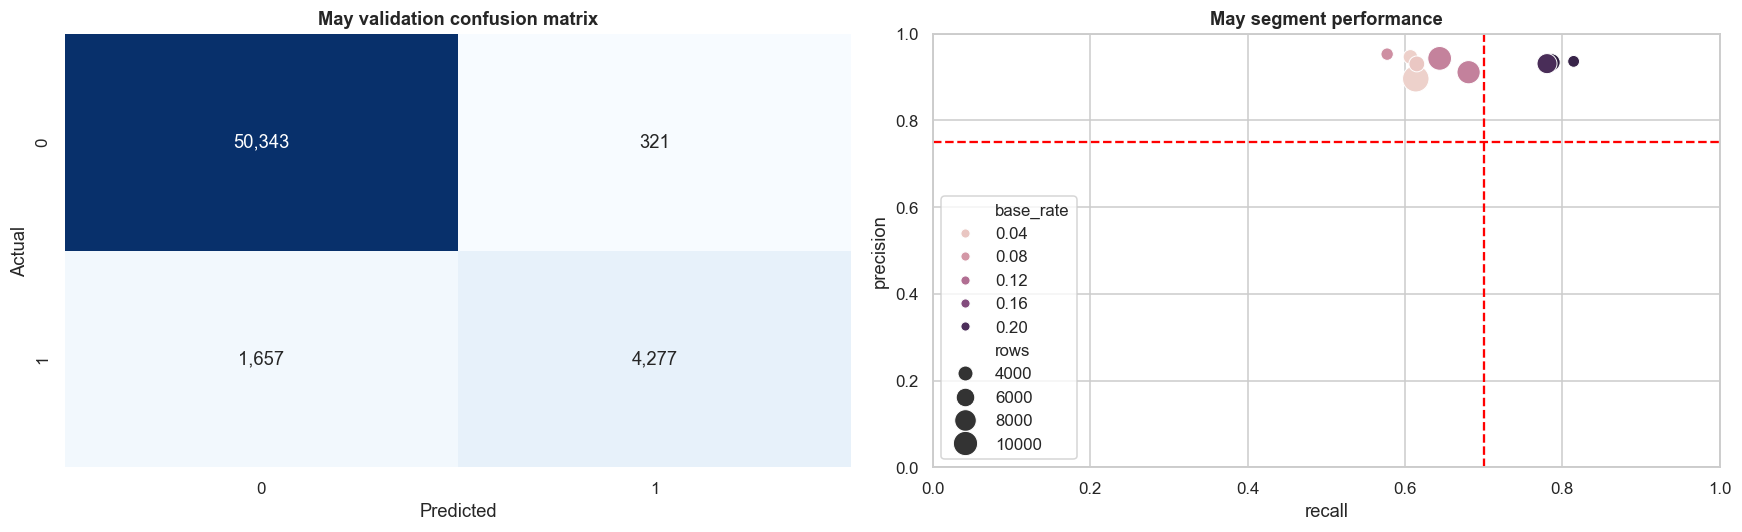

In [9]:
train_may, valid_may = split_fold(panel, MAY_FOLD)
may_parts = []
if selected_architecture == "shared_model":
    _, score = fit_predict(train_may, valid_may, selected_numeric)
    keep = valid_may[["date", "store_id", "sku_id", "channel", "segment_tier", "category", "target", "future_restock_7d", "first_oos_day"]].copy()
    keep["score"] = score; may_parts.append(keep)
else:
    for (channel, tier), vseg in valid_may.groupby(["channel", "segment_tier"], observed=True):
        tseg = train_may.loc[train_may.channel.eq(channel) & train_may.segment_tier.eq(tier)].copy()
        _, score = fit_predict(tseg, vseg, selected_numeric, categorical=["region", "category"])
        keep = vseg[["date", "store_id", "sku_id", "channel", "segment_tier", "category", "target", "future_restock_7d", "first_oos_day"]].copy()
        keep["score"] = score; may_parts.append(keep)
may = pd.concat(may_parts, ignore_index=True)

frozen_thresholds = policy_thresholds[(selected_architecture, selected_policy)]
if selected_policy == "global_threshold":
    may["threshold"] = frozen_thresholds["global"]
else:
    may["segment"] = may.channel.astype(str) + " | " + may.segment_tier.astype(str)
    may["threshold"] = may.segment.map(frozen_thresholds)
may["predicted"] = may.score.ge(may.threshold)

y = may.target.to_numpy(int); pred = may.predicted.to_numpy(bool)
tp = ((y == 1) & pred).sum(); fp = ((y == 0) & pred).sum(); fn = ((y == 1) & ~pred).sum()
may_metrics = pd.DataFrame([{
    "architecture": selected_architecture, "policy": selected_policy, "feature_set": selected_feature_set,
    "evaluation": "May validation", "ROC_AUC": roc_auc_score(y, may.score), "PR_AUC": average_precision_score(y, may.score),
    "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "TP": tp, "FP": fp, "FN": fn, "alerts": pred.sum(),
}])
may_metrics["meets_target"] = may_metrics.precision.ge(MIN_PRECISION) & may_metrics.recall.ge(MIN_RECALL) & may_metrics.ROC_AUC.ge(MIN_AUC)
display(may_metrics.round(4))

segment_metrics = may.groupby(["channel", "segment_tier"], observed=True).apply(lambda d: pd.Series({
    "rows": len(d), "base_rate": d.target.mean(),
    "precision": ((d.target.eq(1)) & d.predicted).sum() / max(d.predicted.sum(), 1),
    "recall": ((d.target.eq(1)) & d.predicted).sum() / max(d.target.eq(1).sum(), 1),
    "FP": ((d.target.eq(0)) & d.predicted).sum(), "alerts": d.predicted.sum(),
})).reset_index()
display(segment_metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
cm = np.array([[((y == 0) & ~pred).sum(), ((y == 0) & pred).sum()], [((y == 1) & ~pred).sum(), ((y == 1) & pred).sum()]])
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="May validation confusion matrix", xlabel="Predicted", ylabel="Actual")
sns.scatterplot(data=segment_metrics, x="recall", y="precision", hue="base_rate", size="rows", sizes=(60, 300), ax=axes[1])
axes[1].axvline(.70, color="red", ls="--"); axes[1].axhline(.75, color="red", ls="--")
axes[1].set(title="May segment performance", xlim=(0, 1), ylim=(0, 1))
plt.tight_layout(); plt.show()

## 8. False-positive replenishment diagnostic

,outcome,rows,mean_score,future_restock_rate,median_first_oos_day
0,FN,1657,0.6976,0.4961,5.0
1,FP,321,0.9408,0.8785,NaN
2,TN,50343,0.0502,0.4088,NaN
3,TP,4277,0.9809,0.4922,1.0


,future_restock_7d,rows,base_rate,alert_rate,false_positive_rate_among_alerts
0,False,32810.0,0.0916,0.0674,0.0176
1,True,23788.0,0.1230,0.1003,0.1181


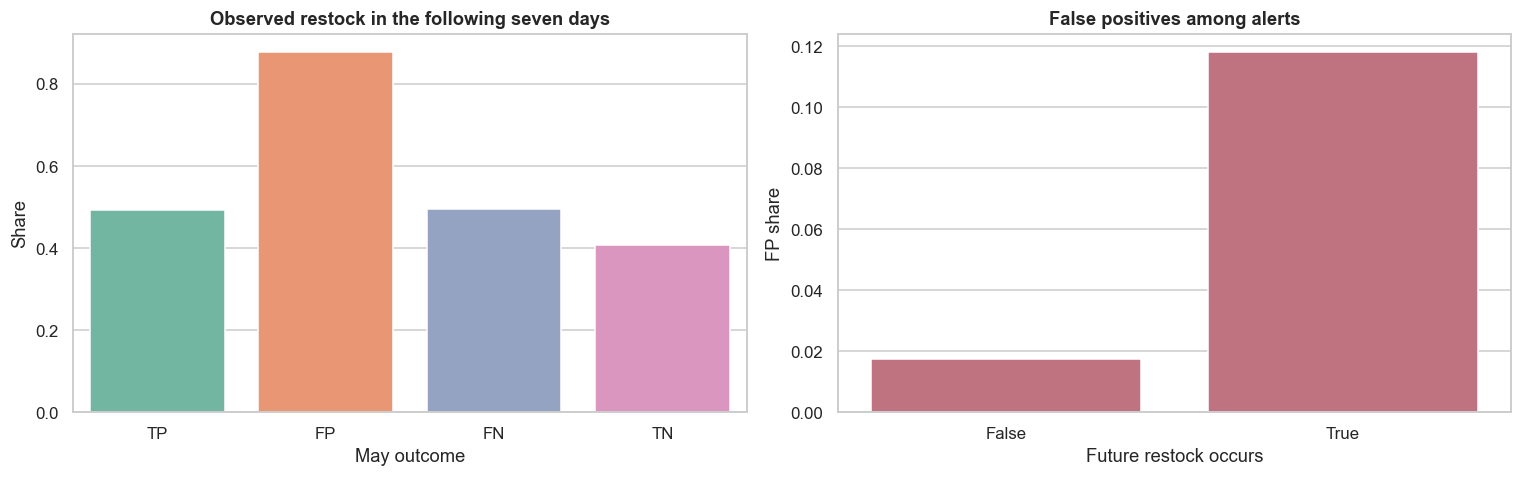

In [10]:
may["outcome"] = np.select(
    [may.predicted & may.target.eq(1), may.predicted & may.target.eq(0), ~may.predicted & may.target.eq(1)],
    ["TP", "FP", "FN"], default="TN",
)
error_diagnostic = may.groupby("outcome", observed=True).agg(
    rows=("target", "size"), mean_score=("score", "mean"), future_restock_rate=("future_restock_7d", "mean"),
    median_first_oos_day=("first_oos_day", "median"),
).reset_index()
display(error_diagnostic.round(4))

# Directly compare false-positive rates with and without a replenishment in the seven-day outcome window.
fp_by_restock = may.groupby("future_restock_7d", observed=True).apply(lambda d: pd.Series({
    "rows": len(d), "base_rate": d.target.mean(), "alert_rate": d.predicted.mean(),
    "false_positive_rate_among_alerts": ((d.target.eq(0)) & d.predicted).sum() / max(d.predicted.sum(), 1),
})).reset_index()
display(fp_by_restock.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=error_diagnostic, x="outcome", y="future_restock_rate", order=["TP", "FP", "FN", "TN"], ax=axes[0], palette="Set2")
axes[0].set(title="Observed restock in the following seven days", ylabel="Share", xlabel="May outcome")
sns.barplot(data=fp_by_restock, x="future_restock_7d", y="false_positive_rate_among_alerts", ax=axes[1], color="#CC6677")
axes[1].set(title="False positives among alerts", xlabel="Future restock occurs", ylabel="FP share")
plt.tight_layout(); plt.show()

## 9. Decision, interpretation, and exports

In [11]:
gate_pass = bool(may_metrics.meets_target.iloc[0])
gate_status = "PASS — eligible for a separately governed June test" if gate_pass else "FAIL — remain in development; June stays locked"
display(Markdown(f"## Validation decision: **{gate_status}**"))

comparison = feature_metrics.loc[feature_metrics.evaluation.eq("March-April pooled"), [
    "feature_set", "ROC_AUC", "PR_AUC", "precision", "recall", "FP"
]].sort_values("precision", ascending=False)
display(Markdown("### What V3 delivery features changed on development folds")); display(comparison.round(4))

metadata = {
    "data_version": "v3", "test_start": str(TEST_START.date()), "test_loaded_or_evaluated": False,
    "selected_feature_set": selected_feature_set, "selected_architecture": selected_architecture,
    "selected_threshold_policy": selected_policy, "validation_gate": gate_status,
    "targets": {"precision": MIN_PRECISION, "recall": MIN_RECALL, "roc_auc": MIN_AUC},
}
feature_metrics.to_csv(OUTPUT / "development_feature_metrics.csv", index=False)
feature_importance.to_csv(OUTPUT / "feature_importance.csv", index=False)
policy_metrics_dev.to_csv(OUTPUT / "development_policy_metrics.csv", index=False)
may_metrics.to_csv(OUTPUT / "may_validation_metrics.csv", index=False)
segment_metrics.to_csv(OUTPUT / "may_segment_metrics.csv", index=False)
error_diagnostic.to_csv(OUTPUT / "may_error_diagnostic.csv", index=False)
fp_by_restock.to_csv(OUTPUT / "may_fp_by_future_restock.csv", index=False)
may.to_csv(OUTPUT / "may_predictions.csv", index=False)
(OUTPUT / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved outputs to", OUTPUT)
print("Locked June evaluated: False")

## Validation decision: **PASS — eligible for a separately governed June test**

### What V3 delivery features changed on development folds

,feature_set,ROC_AUC,PR_AUC,precision,recall,FP
3,v3_replenishment_enriched,0.9879,0.9417,0.9184,0.7501,1160
0,baseline_no_pending_delivery,0.9751,0.8517,0.8091,0.7500,3080


Saved outputs to /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote/outputs/v3/module2
Locked June evaluated: False


## How to interpret the outcome

The comparison between `baseline_no_pending_delivery` and `v3_replenishment_enriched` isolates whether the repaired replenishment information adds predictive value under the same folds and target definition. The segment experiment then asks a separate question: whether heterogeneous base rates are best handled by separate models or by a shared model with segment-specific decision thresholds.

A May pass authorizes a later, separately governed June confirmation. A May failure does not justify looking at June; it identifies the remaining error pattern—especially false positives associated with future restocks—for the next development iteration.